# Mid-Term 2 — Nhóm 7: Red Wine Quality

**Thành viên nhóm 7:**

| STT | Họ và tên | MSSV |
|---|---|---|
| 1 | ……………… | ……………… |
| 2 | ……………… | ……………… |
| 3 | ……………… | ……………… |

**Bối cảnh & mục tiêu bài toán:** Với một doanh nghiệp sản xuất hoặc nhập khẩu rượu vang, câu hỏi quan trọng là *"Điều gì làm nên một chai rượu được chuyên gia chấm điểm cao?"*. Bài này phân tích **11 chỉ số hóa lý** của 1.599 mẫu rượu vang đỏ để tìm ra **những yếu tố quyết định chất lượng**, từ đó đưa ra khuyến nghị cho khâu sản xuất và kiểm soát chất lượng.

Bài làm theo 4 giai đoạn của đề bài:
1. Thu thập và đánh giá dữ liệu ban đầu
2. Tiền xử lý và làm sạch dữ liệu
3. Phân tích và trực quan hóa (kiểm định giả thuyết **+ dùng mô hình học máy để kiểm chứng kết quả**)
4. Đánh giá tác động và khuyến nghị

> **Cách chạy trên Google Colab:** chọn menu *Runtime → Run all*. Dữ liệu được đọc trực tiếp từ Internet nên không cần upload file.

In [ ]:
# Nạp các thư viện cần dùng
import pandas as pd                 # xử lý dữ liệu dạng bảng
import matplotlib.pyplot as plt     # vẽ biểu đồ
import seaborn as sns               # vẽ biểu đồ đẹp hơn (dựa trên matplotlib)
from scipy import stats             # kiểm định thống kê (t-test)

sns.set_theme(style="whitegrid")    # giao diện biểu đồ có lưới nền cho dễ đọc

---
# Giai đoạn 1 — Thu thập và đánh giá dữ liệu ban đầu
## 1.1 Nguồn dữ liệu
- **Tập dữ liệu:** *Red Wine Quality* (Cortez và cộng sự, 2009) — Kaggle: https://www.kaggle.com/datasets/uciml/red-wine-quality-cortez-et-al-2009 (bản gốc lưu tại kho UCI Machine Learning Repository, notebook đọc từ link UCI để chạy được ngay trên Colab).
- **Nội dung:** các mẫu rượu vang đỏ *Vinho Verde* của Bồ Đào Nha; mỗi mẫu được đo 11 chỉ số hóa lý trong phòng thí nghiệm và được chuyên gia chấm điểm cảm quan.
- **Cấu trúc file:** chỉ có **1 file** `winequality-red.csv` → không cần ghép bảng, không có khóa chính/khóa ngoại.
- **Ý nghĩa các thuộc tính:**

| Cột | Ý nghĩa (đơn vị) | Giải thích dễ hiểu |
|---|---|---|
| fixed acidity | Độ axit cố định (g/dm³) | Axit không bay hơi, tạo vị chua chính của rượu |
| volatile acidity | Độ chua bay hơi (g/dm³) | Chủ yếu là axit axetic — quá cao gây **mùi giấm** khó chịu |
| citric acid | Axit citric (g/dm³) | Tạo vị tươi, mát |
| residual sugar | Đường dư (g/dm³) | Đường còn lại sau khi lên men → độ ngọt |
| chlorides | Muối clorua (g/dm³) | Tạo vị mặn |
| free sulfur dioxide | SO₂ tự do (mg/dm³) | Chống vi khuẩn và chống oxy hóa |
| total sulfur dioxide | Tổng SO₂ (mg/dm³) | SO₂ tự do + SO₂ đã liên kết |
| density | Tỷ trọng (g/cm³) | Phụ thuộc lượng cồn và đường |
| pH | Độ pH | Càng nhỏ càng chua |
| sulphates | Sulphat (g/dm³) | Phụ gia bảo quản, góp phần tạo SO₂ |
| alcohol | Nồng độ cồn (% thể tích) | Độ "mạnh" của rượu |
| **quality** | **Điểm chất lượng (0–10)** | **Biến mục tiêu** — trung vị điểm của ít nhất 3 chuyên gia |

- **Mục tiêu bài toán:** xác định các chỉ số hóa lý có ảnh hưởng rõ rệt đến điểm chất lượng và lượng hóa mức độ khác biệt giữa rượu ngon và rượu thường.

In [ ]:
# Đọc dữ liệu trực tiếp từ kho UCI (file CSV, các cột ngăn cách bằng dấu chấm phẩy ";")
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df = pd.read_csv(url, sep=";")

# Xem 5 dòng đầu tiên
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 1.2 Kiểm tra hiện trạng dữ liệu

In [ ]:
# Số quan sát (dòng) và số thuộc tính (cột)
print("Số dòng:", df.shape[0])
print("Số cột: ", df.shape[1])

Số dòng: 1599
Số cột:  12


In [ ]:
# Cấu trúc dữ liệu: tên cột, kiểu dữ liệu, số ô có giá trị (Non-Null)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


**Nhận xét:** dữ liệu có **1.599 quan sát × 12 cột**. Cả 11 chỉ số hóa lý đều là số thực (`float64`), `quality` là số nguyên (`int64`) → **kiểu dữ liệu đúng với ý nghĩa**, không có cột nào bị đọc sai thành chữ (`object`), nên không cần chuyển đổi định dạng.

In [ ]:
# Thống kê mô tả: số lượng, trung bình, độ lệch chuẩn, nhỏ nhất, tứ phân vị, lớn nhất
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.32,1.74,4.60,7.10,7.90,9.20,15.90
volatile acidity,1599.0,0.53,0.18,0.12,0.39,0.52,0.64,1.58
citric acid,1599.0,0.27,0.19,0.00,0.09,0.26,0.42,1.00
residual sugar,1599.0,2.54,1.41,0.90,1.90,2.20,2.60,15.50
chlorides,1599.0,0.09,0.05,0.01,0.07,0.08,0.09,0.61
free sulfur dioxide,1599.0,15.87,10.46,1.00,7.00,14.00,21.00,72.00
total sulfur dioxide,1599.0,46.47,32.90,6.00,22.00,38.00,62.00,289.00
density,1599.0,1.00,0.00,0.99,1.00,1.00,1.00,1.00
pH,1599.0,3.31,0.15,2.74,3.21,3.31,3.40,4.01
sulphates,1599.0,0.66,0.17,0.33,0.55,0.62,0.73,2.00


**Nhận xét:**
- Điểm `quality` chỉ nằm trong khoảng **3 – 8** (dù thang điểm là 0–10), trung bình 5,64 → chuyên gia hầu như không cho điểm quá thấp hoặc quá cao.
- Một số cột có **max lớn hơn rất nhiều so với 75%**, dấu hiệu của ngoại lệ (outlier): `residual sugar` (75% = 2,6 nhưng max = 15,5), `chlorides` (0,09 → 0,61), `total sulfur dioxide` (62 → 289), `sulphates` (0,73 → 2,0). Sẽ kiểm tra kỹ ở Giai đoạn 2.

In [ ]:
# Kiểm tra giá trị khuyết thiếu: số ô trống và tỷ lệ % ở từng cột
bang_thieu = pd.DataFrame({
    "So_o_thieu": df.isnull().sum(),
    "Ty_le_thieu_%": df.isnull().mean() * 100
})
bang_thieu

,So_o_thieu,Ty_le_thieu_%
fixed acidity,0,0.0
volatile acidity,0,0.0
citric acid,0,0.0
residual sugar,0,0.0
chlorides,0,0.0
free sulfur dioxide,0,0.0
total sulfur dioxide,0,0.0
density,0,0.0
pH,0,0.0
sulphates,0,0.0


**Nhận xét:** tỷ lệ giá trị khuyết thiếu ở **tất cả các cột đều bằng 0%** → dữ liệu đầy đủ, không cần điền giá trị thiếu.

In [ ]:
# Kiểm tra dòng trùng lặp (giống hệt một dòng khác ở cả 12 cột)
so_trung = df.duplicated().sum()
print("Số dòng trùng lặp:", so_trung)
print(f"Tỷ lệ trùng lặp: {so_trung / len(df) * 100:.1f}%")

Số dòng trùng lặp: 240
Tỷ lệ trùng lặp: 15.0%


**Nhận xét:** có **240 dòng trùng lặp (15%)** — một tỷ lệ đáng kể, cần xử lý ở Giai đoạn 2.

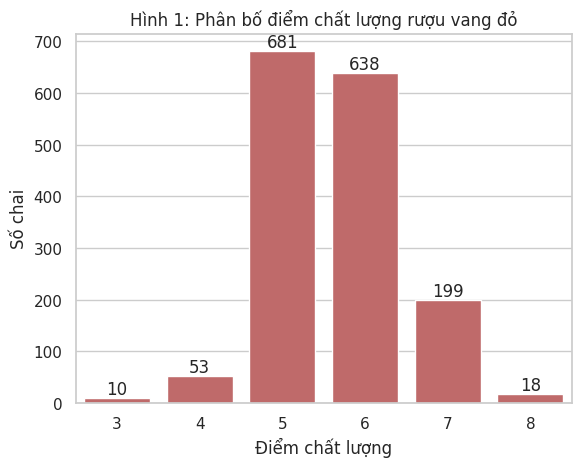

quality
3     0.6
4     3.3
5    42.6
6    39.9
7    12.4
8     1.1
Name: proportion, dtype: float64


In [ ]:
# Hình 1: Số chai rượu ở mỗi mức điểm chất lượng
ax = sns.countplot(data=df, x="quality", color="indianred")
ax.bar_label(ax.containers[0])            # ghi số lượng lên đầu mỗi cột
plt.title("Hình 1: Phân bố điểm chất lượng rượu vang đỏ")
plt.xlabel("Điểm chất lượng")
plt.ylabel("Số chai")
plt.show()

# Tỷ lệ % của từng mức điểm
print((df["quality"].value_counts(normalize=True).sort_index() * 100).round(1))

**Nhận xét Hình 1:**
- Dữ liệu **mất cân bằng mạnh**: điểm 5 và 6 chiếm tới **82,5%** (42,6% + 39,9%). Rượu "ngon" (điểm 7–8) chỉ chiếm **13,5%**, rượu "kém" (điểm 3–4) chỉ **3,9%**.
- Điểm 3 chỉ có 10 mẫu và điểm 8 chỉ có 18 mẫu (dữ liệu gốc; sau khi xóa dòng trùng ở mục 2.1 còn 10 và 17 mẫu) → nếu so sánh từng mức điểm riêng lẻ, kết quả ở hai đầu sẽ kém tin cậy.
- Vì vậy, nhóm **gộp điểm thành các nhóm** (Thấp / Trung bình / Cao) và so sánh bằng **tỷ lệ %, giá trị trung bình** thay vì số lượng tuyệt đối.

---
# Giai đoạn 2 — Tiền xử lý và làm sạch dữ liệu
## 2.1 Dữ liệu trùng lặp

In [ ]:
# Minh chứng: xem vài dòng bị trùng (sắp xếp để các dòng giống nhau đứng cạnh nhau)
df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(6)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
142,5.2,0.34,0.00,1.8,0.050,27.0,63.0,0.9916,3.68,0.79,14.0,6
144,5.2,0.34,0.00,1.8,0.050,27.0,63.0,0.9916,3.68,0.79,14.0,6
131,5.6,0.50,0.09,2.3,0.049,17.0,99.0,0.9937,3.63,0.63,13.0,5
132,5.6,0.50,0.09,2.3,0.049,17.0,99.0,0.9937,3.63,0.63,13.0,5
1488,5.6,0.54,0.04,1.7,0.049,5.0,13.0,0.9942,3.72,0.58,11.4,5
1491,5.6,0.54,0.04,1.7,0.049,5.0,13.0,0.9942,3.72,0.58,11.4,5


In [ ]:
# Xử lý trùng lặp: xóa các dòng trùng, chỉ giữ lại 1 bản
df_sach = df.drop_duplicates().reset_index(drop=True)
print("Trước khi xóa:", df.shape)
print("Sau khi xóa:  ", df_sach.shape)

Trước khi xóa: (1599, 12)
Sau khi xóa:   (1359, 12)


**Giải trình lựa chọn — vì sao XÓA dòng trùng?**
- Các dòng trùng giống nhau ở **cả 12 cột**, trong đó có các số đo lẻ tới 3–4 chữ số thập phân (ví dụ `density` = 0,9916, `chlorides` = 0,050). Hai chai rượu khác nhau gần như không thể trùng khớp tuyệt đối tất cả 11 chỉ số → nhiều khả năng đây là **cùng một mẫu bị ghi lại nhiều lần**.
- Nếu giữ lại, các mẫu này được "đếm 2 lần", làm **sai lệch** trung bình, tỷ lệ % và kết quả kiểm định.
- Sau khi xóa còn **1.359 mẫu** — vẫn đủ lớn để phân tích.

## 2.2 Giá trị khuyết thiếu và lựa chọn Mean / Median
Dữ liệu **không có giá trị thiếu** (đã kiểm tra ở mục 1.2), nên không cần điền. Tuy nhiên, nhóm vẫn kiểm tra hình dạng phân phối để biết **nếu cần điền thì nên dùng Mean hay Median**, đồng thời chuẩn bị cho việc xử lý ngoại lệ.

In [ ]:
# So sánh Mean (trung bình) và Median (trung vị) của từng biến
# Skew (độ lệch) > 1: phân phối lệch phải mạnh -> Mean bị kéo lên bởi các giá trị rất lớn
bang_lech = pd.DataFrame({
    "Mean": df_sach.mean(),
    "Median": df_sach.median(),
    "Skew": df_sach.skew()
}).round(2)
bang_lech.sort_values("Skew", ascending=False)

,Mean,Median,Skew
chlorides,0.09,0.08,5.50
residual sugar,2.52,2.20,4.55
sulphates,0.66,0.62,2.41
total sulfur dioxide,46.83,38.00,1.54
free sulfur dioxide,15.89,14.00,1.23
fixed acidity,8.31,7.90,0.94
alcohol,10.43,10.20,0.86
volatile acidity,0.53,0.52,0.73
citric acid,0.27,0.26,0.31
pH,3.31,3.31,0.23


**Nhận xét & giải trình:**
- Nhiều biến **lệch phải mạnh** (Skew > 1): `chlorides` (5,50), `residual sugar` (4,55), `sulphates` (2,41), `total sulfur dioxide` (1,54), `free sulfur dioxide` (1,23). Ở các biến này **Mean > Median** rõ rệt, ví dụ `total sulfur dioxide`: Mean = 46,8 nhưng Median chỉ 38.
- Nguyên nhân: một số ít mẫu có giá trị rất lớn "kéo" giá trị trung bình lên.
- **Kết luận:** nếu có dữ liệu thiếu, nhóm sẽ điền bằng **Median** vì Median không bị ảnh hưởng bởi giá trị cực đoan, phản ánh đúng "mẫu điển hình" hơn Mean.

## 2.3 Ngoại lệ (Outliers)

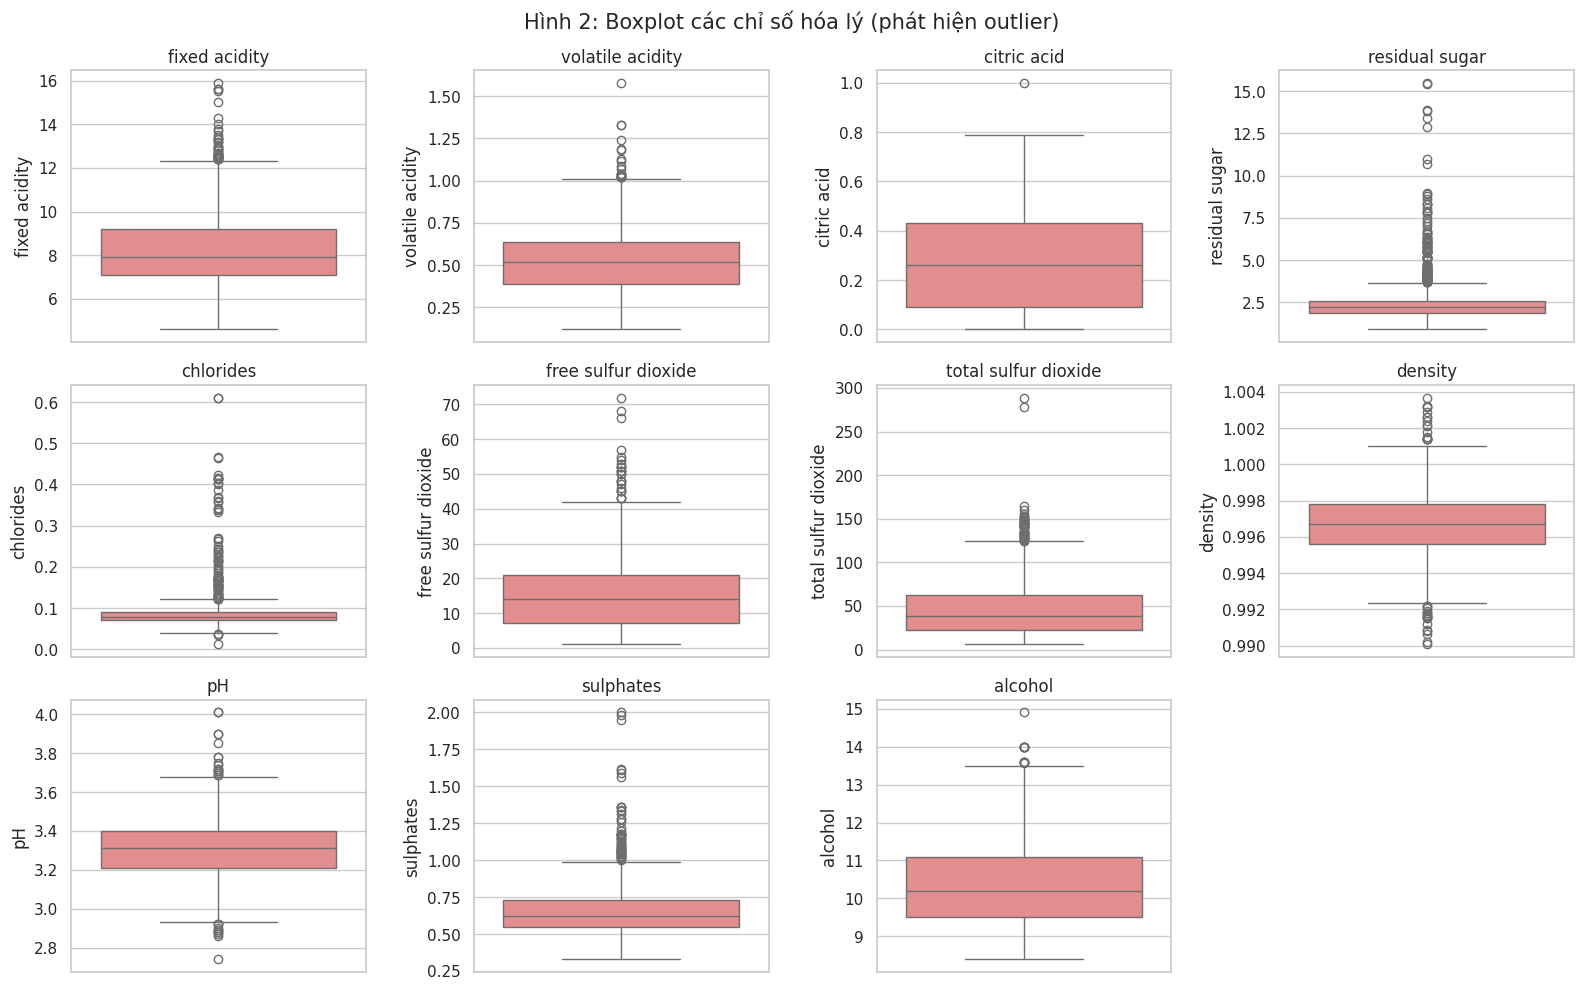

In [ ]:
# Hình 2: Boxplot 11 chỉ số hóa lý - các chấm nằm ngoài "râu" là outlier
cac_bien = df_sach.columns.drop("quality")       # 11 biến hóa lý (bỏ cột quality)

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, bien in zip(axes.flat, cac_bien):         # vẽ lần lượt từng biến vào từng ô
    sns.boxplot(y=df_sach[bien], ax=ax, color="lightcoral")
    ax.set_title(bien)
axes.flat[-1].axis("off")                         # ô thứ 12 để trống
plt.suptitle("Hình 2: Boxplot các chỉ số hóa lý (phát hiện outlier)", fontsize=15)
plt.tight_layout()
plt.show()

In [ ]:
# Đếm outlier bằng phương pháp IQR
# Outlier = giá trị nhỏ hơn Q1 - 1.5*IQR hoặc lớn hơn Q3 + 1.5*IQR  (với IQR = Q3 - Q1)
Q1 = df_sach[cac_bien].quantile(0.25)
Q3 = df_sach[cac_bien].quantile(0.75)
IQR = Q3 - Q1
la_outlier = (df_sach[cac_bien] < Q1 - 1.5 * IQR) | (df_sach[cac_bien] > Q3 + 1.5 * IQR)

bang_outlier = pd.DataFrame({
    "So_outlier": la_outlier.sum(),
    "Ty_le_%": (la_outlier.mean() * 100).round(1)
}).sort_values("So_outlier", ascending=False)
print(bang_outlier)

co_outlier = la_outlier.any(axis=1)               # chai có ít nhất 1 chỉ số là outlier
print(f"\nSố chai có ít nhất 1 outlier: {co_outlier.sum()} / {len(df_sach)} ({co_outlier.mean()*100:.1f}%)")

                      So_outlier  Ty_le_%
residual sugar               126      9.3
chlorides                     87      6.4
sulphates                     55      4.0
total sulfur dioxide          45      3.3
fixed acidity                 41      3.0
density                       35      2.6
pH                            28      2.1
free sulfur dioxide           26      1.9
volatile acidity              19      1.4
alcohol                       12      0.9
citric acid                    1      0.1

Số chai có ít nhất 1 outlier: 340 / 1359 (25.0%)


**Nhận xét Hình 2 & bảng IQR:**
- Outlier tập trung nhiều nhất ở `residual sugar` (**126 mẫu, 9,3%**), `chlorides` (87 mẫu, 6,4%) và `sulphates` (55 mẫu, 4,0%) — đúng các biến lệch phải mạnh ở mục 2.2.
- Tổng cộng **340/1.359 chai (25%)** có ít nhất một chỉ số là outlier.

In [ ]:
# Nếu xóa các chai có outlier thì có làm mất thông tin không?
# So sánh tỷ lệ % từng mức điểm giữa chai CÓ outlier và chai KHÔNG có outlier
pd.crosstab(co_outlier.rename("Có outlier?"), df_sach["quality"], normalize="index").mul(100).round(1)

quality,3,4,5,6,7,8
Có outlier?,,,,,,
False,0.3,3.2,42.6,41.5,11.3,1.1
True,2.1,5.9,42.1,32.9,15.3,1.8


**Giải trình lựa chọn — vì sao GIỮ LẠI outlier (không xóa)?**
1. **Không phải lỗi nhập liệu:** các giá trị lớn nhất (đường dư 15,5 g/dm³, sulphates 2,0 g/dm³…) vẫn **có thể xảy ra trong thực tế** sản xuất rượu (ví dụ rượu hơi ngọt, rượu được thêm nhiều chất bảo quản). Không có giá trị vô lý như số âm hay pH > 14.
2. **Xóa sẽ mất quá nhiều dữ liệu:** 25% số mẫu.
3. **Outlier mang thông tin quan trọng:** bảng trên cho thấy nhóm chai có outlier có tỷ lệ **điểm 3 cao gấp 7 lần** (2,1% so với 0,3%) và tỷ lệ **điểm 7 cũng cao hơn** (15,3% so với 11,3%). Nghĩa là outlier thường rơi vào các chai ở hai đầu chất lượng; nếu xóa sẽ mất phần lớn mẫu rượu kém.
4. Các công cụ phân tích ở Giai đoạn 3 (Boxplot, Median, Welch t-test trên nhóm lớn) ít bị outlier ảnh hưởng.

In [ ]:
# Phân tích độ nhạy: kết luận chính có thay đổi khi đổi cách làm sạch dữ liệu không?
# Tính lại hệ số tương quan của 4 chỉ số trong giả thuyết H1-H4 với quality trên 3 phiên bản dữ liệu
bien_kiem_tra = ["alcohol", "volatile acidity", "sulphates", "residual sugar"]
cac_phien_ban = {
    "Gốc (chưa xóa trùng)": df,
    "Đã xóa trùng (bản dùng chính)": df_sach,
    "Xóa trùng + bỏ chai có outlier": df_sach[~co_outlier],
}
bang_do_nhay = pd.DataFrame({ten: d[bien_kiem_tra].corrwith(d["quality"])
                             for ten, d in cac_phien_ban.items()}).T.round(3)
bang_do_nhay.insert(0, "So_chai", [len(d) for d in cac_phien_ban.values()])
bang_do_nhay.insert(1, "Ty_le_ruou_ngon_%", [round((d["quality"] >= 7).mean() * 100, 1)
                                             for d in cac_phien_ban.values()])
bang_do_nhay

,So_chai,Ty_le_ruou_ngon_%,alcohol,volatile acidity,sulphates,residual sugar
Gốc (chưa xóa trùng),1599,13.6,0.476,-0.391,0.251,0.014
Đã xóa trùng (bản dùng chính),1359,13.5,0.480,-0.395,0.249,0.014
Xóa trùng + bỏ chai có outlier,1019,12.4,0.515,-0.353,0.423,0.018


**Nhận xét phân tích độ nhạy — hai quyết định làm sạch có làm thay đổi kết luận không?**
- **Xóa dòng trùng** gần như không làm đổi kết quả: alcohol +0,476 → +0,480, volatile acidity −0,391 → −0,395, sulphates +0,251 → +0,249. Sau khi xóa trùng, các mẫu không còn bị đếm hai lần và kết luận vẫn giữ nguyên.
- **Bỏ toàn bộ chai có outlier** (1359 → 1019 chai): **chiều** của cả 4 quan hệ giữ nguyên (alcohol dương, volatile acidity âm, sulphates dương, residual sugar ≈ 0) → kết luận về H1–H4 **không phụ thuộc** vào cách xử lý outlier.
- Tuy nhiên, tương quan của **sulphates tăng mạnh** từ +0,249 lên +0,423 và vượt lên trên volatile acidity. Lý do: các chai có sulphates rất cao chủ yếu là rượu kém (mục 3.3). Nếu xóa các chai này, tương quan của sulphates sẽ **cao hơn thực tế** và nhóm sẽ không thấy được việc dùng quá nhiều sulphates không làm rượu ngon hơn.
- Ngoài ra, bỏ outlier làm tỷ lệ rượu ngon giảm từ 13,5% xuống 12,4%.
- Từ bảng này, nhóm **giữ nguyên quyết định không xóa outlier**: các kết luận chính không đổi dù xử lý theo cách nào, còn nếu xóa thì kết quả về sulphates sẽ bị sai lệch.

## 2.4 Biến đổi dữ liệu: tạo nhóm chất lượng

In [ ]:
# Tạo cột "nhom" (nhóm chất lượng) để so sánh dễ hơn:
# Thấp: điểm 3-5 | Trung bình: điểm 6 | Cao: điểm 7-8
df_sach["nhom"] = pd.cut(df_sach["quality"], bins=[0, 5, 6, 10],
                         labels=["Thấp (≤5)", "Trung bình (6)", "Cao (≥7)"])
df_sach["nhom"].value_counts().sort_index()

,count
nhom,
Thấp (≤5),640
Trung bình (6),535
Cao (≥7),184


**Giải trình lựa chọn kỹ thuật:**
- **Tạo nhóm chất lượng** (*binning* bằng `pd.cut`): Thấp (≤5) = 640 mẫu, Trung bình (6) = 535 mẫu, Cao (≥7) = 184 mẫu. Lý do: điểm 3, 4, 8 có quá ít mẫu (mục 1.2), gộp nhóm giúp so sánh ổn định hơn. Mốc 7 được chọn vì đây là ngưỡng thường dùng để gọi là rượu "ngon" (*good wine*).
- **Không cần mã hóa (encoding):** tất cả các biến đều là số, không có biến dạng chữ (như giới tính, tên vùng…) nên không cần One-hot hay Label Encoding.
- **Không cần chuẩn hóa (scaling):** Giai đoạn 3 chỉ so sánh từng biến riêng lẻ giữa các nhóm và tính hệ số tương quan — các phép tính này **không bị ảnh hưởng bởi đơn vị đo**. Mô hình kiểm chứng ở mục 3.6 là **Random Forest** — mô hình này chia dữ liệu bằng các câu hỏi ngưỡng (ví dụ "cồn > 10,5%?") nên **cũng không bị ảnh hưởng bởi đơn vị đo**, không cần chuẩn hóa.

---
# Giai đoạn 3 — Phân tích và trực quan hóa
## 3.1 Câu hỏi nghiên cứu và giả thuyết ban đầu
**Câu hỏi:** Chỉ số hóa lý nào phân biệt rượu ngon với rượu thường?

Dựa trên hiểu biết chung về rượu vang, nhóm đặt ra 4 giả thuyết **trước khi** xem số liệu:

| Giả thuyết | Nội dung | Kỳ vọng |
|---|---|---|
| **H1** | Rượu có **nồng độ cồn** cao hơn được chấm điểm cao hơn | Tương quan dương |
| **H2** | Rượu có **độ chua bay hơi** (mùi giấm) cao bị chấm điểm thấp hơn | Tương quan âm |
| **H3** | Rượu có **sulphates** (chất bảo quản) cao hơn được chấm điểm cao hơn (giữ rượu tươi lâu hơn) | Tương quan dương |
| **H4** | **Đường dư** (độ ngọt) **không** ảnh hưởng đáng kể đến điểm của rượu vang đỏ (vốn là rượu khô) | Không khác biệt |

Quy trình kiểm tra: **Tương quan (Hình 3–4) → So sánh theo nhóm (Hình 5–6) → Kết hợp 2 yếu tố (Hình 7) → Kiểm định thống kê (mục 3.5) → Kiểm chứng bằng mô hình (mục 3.6) → Tổng hợp theo từng giả thuyết (mục 3.7)**.

## 3.2 Bức tranh tổng thể: tương quan giữa các biến

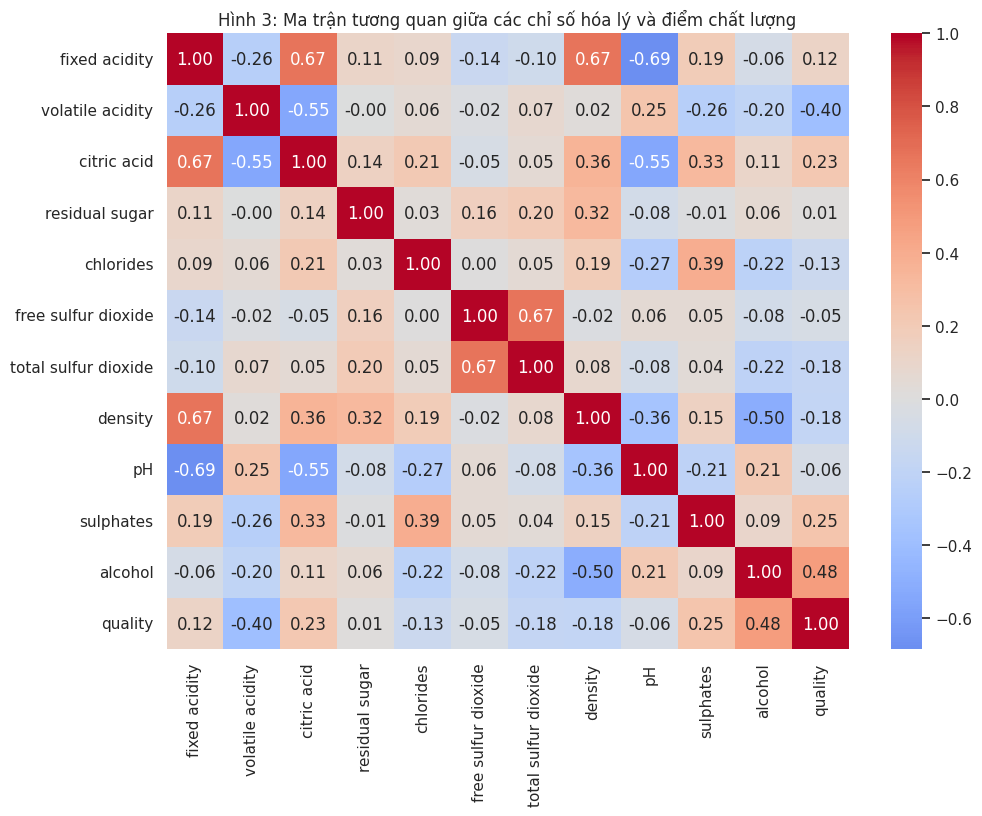

In [ ]:
# Hình 3: Ma trận tương quan (hệ số từ -1 đến 1) giữa 11 chỉ số và điểm chất lượng
tuong_quan = df_sach[list(cac_bien) + ["quality"]].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(tuong_quan, annot=True, fmt=".2f", cmap="coolwarm", center=0)  # đỏ = dương, xanh = âm
plt.title("Hình 3: Ma trận tương quan giữa các chỉ số hóa lý và điểm chất lượng")
plt.show()

**Nhận xét Hình 3:**
- **Với điểm chất lượng (dòng cuối):** tương quan mạnh nhất là `alcohol` (**+0,48**) và `volatile acidity` (**−0,39**), tiếp theo là `sulphates` (+0,25) và `citric acid` (+0,23). Không có biến nào tương quan trên 0,5 → chất lượng rượu là kết quả của **nhiều yếu tố cộng lại**, không có "công thức một biến".
- **Giữa các chỉ số với nhau:** nhóm các biến về axit đi cùng nhau — `fixed acidity` với `pH` (−0,69), với `citric acid` (+0,67), với `density` (+0,67). `free` và `total sulfur dioxide` tương quan +0,67 (vì tổng SO₂ bao gồm SO₂ tự do).
- `alcohol` và `density` tương quan **−0,50** (cồn nhẹ hơn nước nên rượu nhiều cồn có tỷ trọng thấp). Vì vậy tương quan âm của `density` với điểm (−0,18) **phần lớn là do nồng độ cồn**, nên nhóm không xem tỷ trọng là một yếu tố ảnh hưởng riêng.

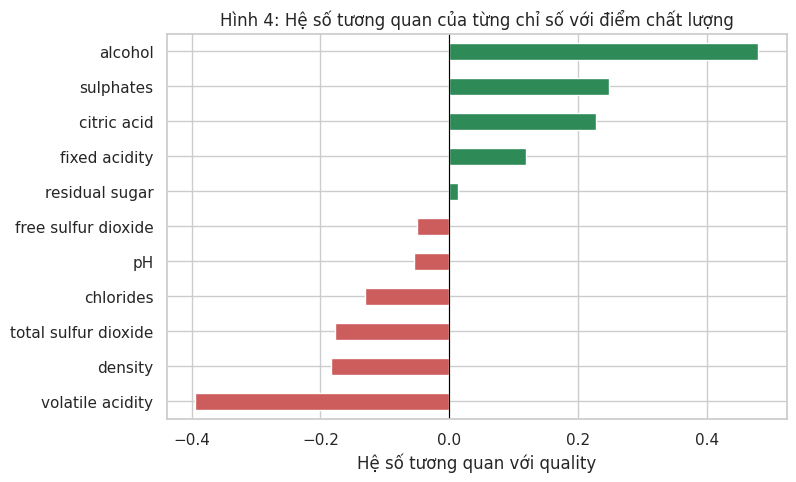

alcohol                 0.480
sulphates               0.249
citric acid             0.228
fixed acidity           0.119
residual sugar          0.014
free sulfur dioxide    -0.050
pH                     -0.055
chlorides              -0.131
total sulfur dioxide   -0.178
density                -0.184
volatile acidity       -0.395
Name: quality, dtype: float64


In [ ]:
# Hình 4: Tương quan của từng chỉ số với điểm chất lượng (sắp xếp từ âm nhất đến dương nhất)
tq_quality = tuong_quan["quality"].drop("quality").sort_values()
mau = ["seagreen" if x > 0 else "indianred" for x in tq_quality]   # dương = xanh, âm = đỏ

tq_quality.plot(kind="barh", color=mau, figsize=(8, 5))
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Hình 4: Hệ số tương quan của từng chỉ số với điểm chất lượng")
plt.xlabel("Hệ số tương quan với quality")
plt.show()

print(tq_quality.sort_values(ascending=False).round(3))

**Nhận xét Hình 4:**
- Xếp hạng rõ ràng: **alcohol (+0,48) > volatile acidity (−0,39) > sulphates (+0,25) > citric acid (+0,23)** — 4 biến này có ảnh hưởng đáng chú ý nhất.
- Kết quả ban đầu **ủng hộ H1, H2, H3** (đúng dấu kỳ vọng).
- `residual sugar` có tương quan gần như bằng **0 (+0,014)** → ủng hộ **H4**. Tương tự `free sulfur dioxide` (−0,05) và `pH` (−0,06) hầu như không liên quan đến điểm.
- **Ý nghĩa thực tế:** khi kiểm soát chất lượng, doanh nghiệp có thể ưu tiên theo dõi 3–4 chỉ số này trước.

## 3.3 So sánh theo nhóm chất lượng (kiểm tra H1 – H4)

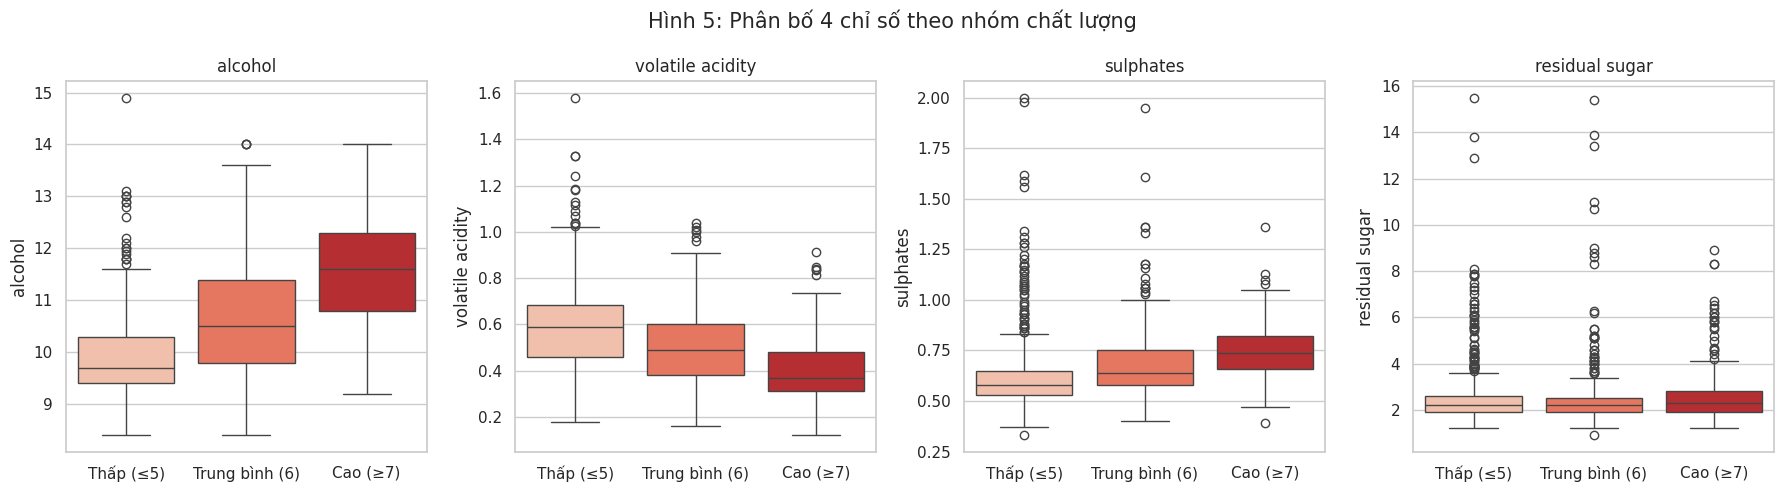

In [ ]:
# Hình 5: So sánh 4 chỉ số trong giả thuyết H1-H4 giữa 3 nhóm chất lượng
bien_gia_thuyet = ["alcohol", "volatile acidity", "sulphates", "residual sugar"]

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, bien in zip(axes, bien_gia_thuyet):
    sns.boxplot(data=df_sach, x="nhom", y=bien, hue="nhom", palette="Reds", legend=False, ax=ax)
    ax.set_title(bien)
    ax.set_xlabel("")
plt.suptitle("Hình 5: Phân bố 4 chỉ số theo nhóm chất lượng", fontsize=15)
plt.tight_layout()
plt.show()

In [ ]:
# Bảng giá trị trung bình của 4 chỉ số theo từng nhóm chất lượng
df_sach.groupby("nhom", observed=True)[bien_gia_thuyet].mean().round(3)

,alcohol,volatile acidity,sulphates,residual sugar
nhom,,,,
Thấp (≤5),9.921,0.593,0.620,2.527
Trung bình (6),10.659,0.496,0.675,2.457
Cao (≥7),11.553,0.406,0.746,2.704


**Nhận xét Hình 5 & bảng trung bình:**
- **H1 – Nồng độ cồn:** tăng đều qua 3 nhóm: **9,92% → 10,66% → 11,55%**. Hộp của nhóm Cao nằm gần như hoàn toàn phía trên trung vị của nhóm Thấp → khác biệt rất rõ.
- **H2 – Độ chua bay hơi:** giảm đều **0,593 → 0,496 → 0,406**. Rượu nhóm Cao có mùi giấm ít hơn nhóm Thấp khoảng **32%**.
- **H3 – Sulphates:** tăng **0,620 → 0,675 → 0,746**. Riêng các outlier sulphates rất cao (1,5–2,0) lại nằm chủ yếu ở **nhóm Thấp** (5/7 chai, không chai nào thuộc nhóm Cao) → gợi ý rằng dùng **quá nhiều** sulphates chưa chắc làm rượu ngon hơn. Nhóm kiểm tra thêm điều này ở bảng dưới đây.
- **H4 – Đường dư:** trung bình 3 nhóm gần như nhau (**2,53 / 2,46 / 2,70**), không tăng/giảm theo một chiều và các hộp chồng lên nhau gần hoàn toàn → độ ngọt **không** phân biệt được chất lượng.

In [ ]:
# Kiểm tra thêm cho H3: sulphates ở mức nào thì tỷ lệ rượu ngon cao nhất?
# Chia sulphates thành 6 khoảng; với mỗi khoảng tính số chai, điểm trung bình và tỷ lệ % rượu ngon (điểm >= 7)
khoang_sulphates = pd.cut(df_sach["sulphates"], bins=[0, 0.55, 0.65, 0.75, 0.85, 1.0, 2.1])
bang_sulphates = df_sach.groupby(khoang_sulphates, observed=True)["quality"].agg(
    So_chai="size",
    Diem_TB="mean",
    Ty_le_ruou_ngon=lambda q: (q >= 7).mean() * 100    # đơn vị: %
).round(2)
bang_sulphates

,So_chai,Diem_TB,Ty_le_ruou_ngon
sulphates,,,
"(0.0, 0.55]",357,5.23,3.36
"(0.55, 0.65]",465,5.52,7.31
"(0.65, 0.75]",250,5.92,21.20
"(0.75, 0.85]",156,6.19,34.62
"(0.85, 1.0]",77,6.04,28.57
"(1.0, 2.1]",54,5.57,16.67


**Nhận xét bảng sulphates:**
- Tỷ lệ rượu ngon **tăng dần** theo sulphates: 3,4% (≤ 0,55) → 7,3% → 21,2% → **cao nhất 34,6% ở khoảng 0,75–0,85** (điểm trung bình cũng cao nhất: 6,19).
- Vượt quá 0,85, tỷ lệ rượu ngon **giảm** còn 28,6% (0,85–1,0) và chỉ **16,7%** khi sulphates > 1,0 (điểm trung bình 5,57) — thấp hơn cả khoảng 0,65–0,75.
- Như vậy, sulphates **không phải càng nhiều càng tốt**: tỷ lệ rượu ngon tăng đến khoảng **0,65–0,85**, sau đó giảm xuống. Đây là cơ sở cho khuyến nghị dùng sulphates ở mức vừa phải (mục 4.2).
- **Lưu ý:** khoảng > 1,0 chỉ có 54 chai nên kết luận ở đầu này cần thận trọng.

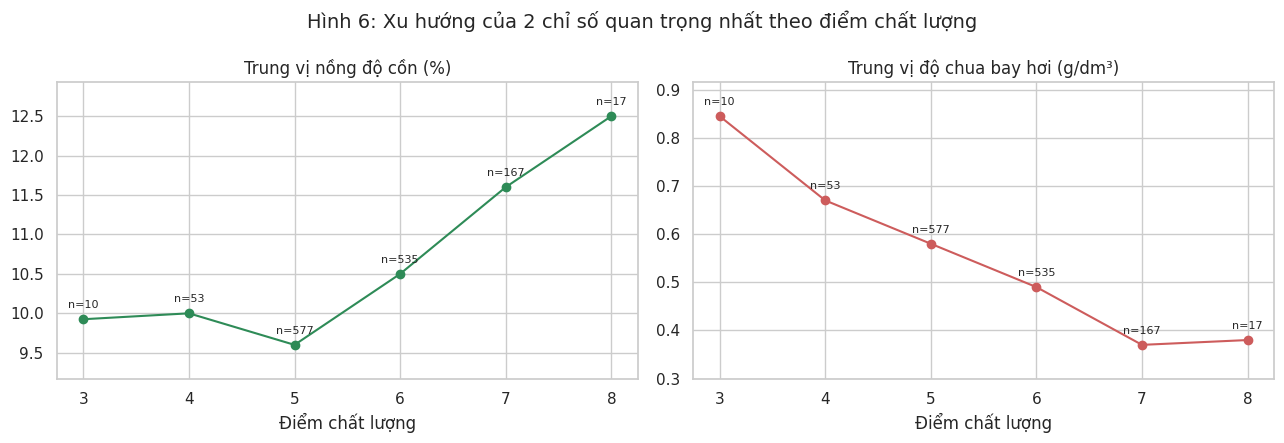

,alcohol,volatile acidity
quality,,
3,9.925,0.845
4,10.000,0.670
5,9.600,0.580
6,10.500,0.490
7,11.600,0.370
8,12.500,0.380


In [ ]:
# Hình 6: TRUNG VỊ nồng độ cồn và độ chua bay hơi theo từng mức điểm (3 -> 8)
# Dùng trung vị thay vì trung bình vì dữ liệu lệch phải (nhất quán với lựa chọn Median ở mục 2.2)
tv_theo_diem = df_sach.groupby("quality")[["alcohol", "volatile acidity"]].median()
so_chai = df_sach["quality"].value_counts().sort_index()      # số chai ở mỗi mức điểm

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, bien, mau in zip(axes, ["alcohol", "volatile acidity"], ["seagreen", "indianred"]):
    tv_theo_diem[bien].plot(ax=ax, marker="o", color=mau)
    for diem, gia_tri in tv_theo_diem[bien].items():           # ghi số chai lên từng điểm
        ax.annotate(f"n={so_chai[diem]}", (diem, gia_tri), textcoords="offset points",
                    xytext=(0, 8), ha="center", fontsize=8)
    ax.margins(y=0.15)                                         # chừa khoảng trống cho nhãn n
    ax.set_xlabel("Điểm chất lượng")
axes[0].set_title("Trung vị nồng độ cồn (%)")
axes[1].set_title("Trung vị độ chua bay hơi (g/dm³)")
plt.suptitle("Hình 6: Xu hướng của 2 chỉ số quan trọng nhất theo điểm chất lượng", fontsize=14)
plt.tight_layout()
plt.show()

tv_theo_diem.round(3)

**Nhận xét Hình 6:**
- Hình dùng **trung vị** thay vì trung bình vì các chỉ số bị lệch (mục 2.2); số `n` trên mỗi điểm là số chai ở mức điểm đó.
- **Nồng độ cồn** gần như **đi ngang** ở các mức điểm 3–5 (trung vị khoảng 9,6–10,0%), sau đó **tăng mạnh** từ điểm 6 trở lên: 10,5% → 11,6% → **12,5%** (điểm 8). → Cồn giúp rượu **từ "khá" lên "ngon"**, nhưng không giải thích được vì sao rượu bị điểm kém.
- **Độ chua bay hơi** giảm đều: **0,845** (điểm 3) → 0,67 → 0,58 → 0,49 → **0,37** (điểm 7); điểm 8 gần như bằng điểm 7 (0,38).
- **Lưu ý cỡ mẫu:** điểm 3 chỉ có 10 chai và điểm 8 chỉ có 17 chai nên giá trị ở hai đầu kém ổn định — ví dụ trung vị cồn ở điểm 3–4 (9,9–10,0%) nhỉnh hơn điểm 5 (9,6%) có thể chỉ là dao động ngẫu nhiên.
- **Từ hình này, nhóm nhận thấy** hai yếu tố có **vai trò khác nhau**:
  - *Độ chua bay hơi là "điểm trừ"*: quyết định rượu có **bị chấm kém** hay không (lỗi kỹ thuật).
  - *Nồng độ cồn là "điểm cộng"*: quyết định rượu có **vượt lên thành rượu ngon** hay không.
  - Nhóm kiểm tra lại nhận định này bằng thống kê ở cuối mục 3.5.

## 3.4 Kết hợp hai yếu tố quan trọng nhất

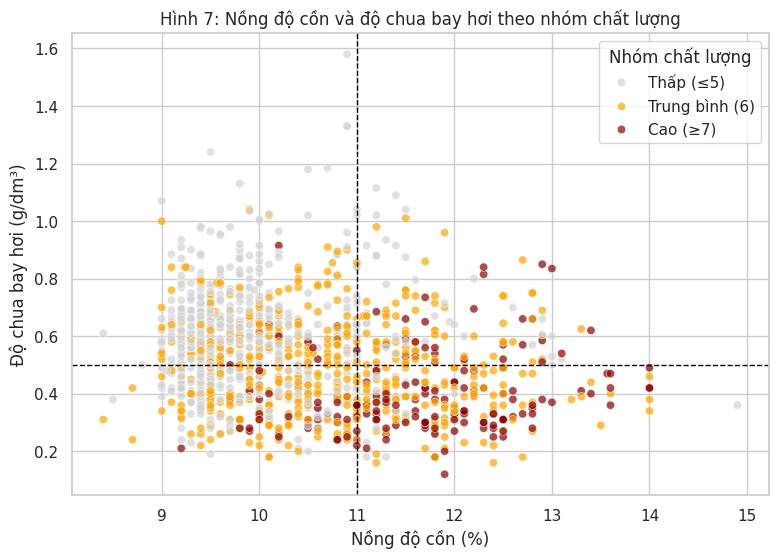

In [ ]:
# Hình 7: Biểu đồ phân tán nồng độ cồn - độ chua bay hơi, tô màu theo nhóm chất lượng
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df_sach, x="alcohol", y="volatile acidity", hue="nhom",
                palette=["lightgray", "orange", "darkred"], alpha=0.7)
plt.axvline(11, color="black", linestyle="--", linewidth=1)    # ngưỡng cồn 11%
plt.axhline(0.5, color="black", linestyle="--", linewidth=1)   # ngưỡng độ chua 0.5
plt.legend(title="Nhóm chất lượng")
plt.title("Hình 7: Nồng độ cồn và độ chua bay hơi theo nhóm chất lượng")
plt.xlabel("Nồng độ cồn (%)")
plt.ylabel("Độ chua bay hơi (g/dm³)")
plt.show()

In [ ]:
# "Vùng rượu ngon": nồng độ cồn > 11% VÀ độ chua bay hơi < 0.5
vung_tot = (df_sach["alcohol"] > 11) & (df_sach["volatile acidity"] < 0.5)
ngon = df_sach["quality"] >= 7                     # rượu ngon = điểm từ 7 trở lên

print(f"Số chai trong vùng: {vung_tot.sum()} ({vung_tot.mean()*100:.1f}% tổng số chai)")
print(f"Tỷ lệ rượu ngon TRONG vùng:  {ngon[vung_tot].mean()*100:.1f}%")
print(f"Tỷ lệ rượu ngon NGOÀI vùng:  {ngon[~vung_tot].mean()*100:.1f}%")
print(f"Vùng này chứa {ngon[vung_tot].sum() / ngon.sum()*100:.1f}% tổng số rượu ngon")

Số chai trong vùng: 222 (16.3% tổng số chai)
Tỷ lệ rượu ngon TRONG vùng:  43.2%
Tỷ lệ rượu ngon NGOÀI vùng:  7.7%
Vùng này chứa 52.2% tổng số rượu ngon


**Nhận xét Hình 7:**
- Các chấm đỏ đậm (nhóm Cao) tập trung ở **góc dưới bên phải**: nhiều cồn (> 11%) và ít vị giấm (< 0,5). Các chấm xám (nhóm Thấp) tập trung ở **góc trên bên trái**.
- "Vùng rượu ngon" (cồn > 11% **và** độ chua bay hơi < 0,5) chỉ gồm **222 chai (16,3%)** nhưng:
  - Tỷ lệ rượu ngon trong vùng là **43,2%**, so với chỉ **7,7%** ở ngoài vùng → **cao gấp khoảng 5,6 lần**.
  - Vùng này chứa **52,2%** tổng số rượu ngon của toàn bộ dữ liệu.
- **Ứng dụng:** chỉ cần 2 chỉ số này là có thể **sàng lọc nhanh** để ưu tiên các lô rượu có khả năng đạt điểm cao.
- **Lưu ý:** hai ngưỡng 11% và 0,5 được nhóm chọn sau khi quan sát Hình 7, rồi đánh giá trên **chính dữ liệu đó**, nên tỷ lệ 43,2% có thể **hơi lạc quan** khi áp dụng cho lô rượu mới. Cần kiểm tra lại trên dữ liệu mới trước khi dùng làm tiêu chuẩn chính thức.

## 3.5 Kiểm định giả thuyết bằng thống kê (t-test)

Biểu đồ cho thấy có khác biệt, nhưng cần kiểm chứng: **khác biệt đó là thật hay chỉ do ngẫu nhiên?**
- Chia dữ liệu thành 2 nhóm: **rượu ngon** (điểm ≥ 7, 184 mẫu) và **rượu thường** (điểm ≤ 6, 1.175 mẫu).
- Dùng **Welch t-test** so sánh trung bình 2 nhóm. Chọn Welch (thay vì t-test thông thường) vì 2 nhóm có **cỡ mẫu chênh lệch lớn** và **độ phân tán khác nhau** (thấy ở Hình 5).
- Cách đọc: **p-value < 0,05** → khác biệt có ý nghĩa thống kê (độ tin cậy 95%).
- Sau đó **kiểm tra lại độ vững** của kết quả: kiểm tra phân phối chuẩn (Shapiro-Wilk) và chạy thêm một kiểm định không cần giả định phân phối chuẩn (Mann-Whitney).

In [ ]:
# Kiểm định t (Welch t-test): trung bình của nhóm rượu ngon (≥7) và rượu thường (≤6) có khác nhau thật không?
# Nếu p-value < 0.05 -> khác biệt có ý nghĩa thống kê (không phải do ngẫu nhiên)
nhom_ngon = df_sach[df_sach["quality"] >= 7]
nhom_thuong = df_sach[df_sach["quality"] <= 6]

ket_qua = []
for bien in bien_gia_thuyet:
    t, p = stats.ttest_ind(nhom_ngon[bien], nhom_thuong[bien], equal_var=False)
    ket_qua.append([bien, nhom_ngon[bien].mean(), nhom_thuong[bien].mean(), p])

bang_kd = pd.DataFrame(ket_qua, columns=["Bien", "TB_ruou_ngon", "TB_ruou_thuong", "p_value"])
bang_kd["Chenh_lech_%"] = (bang_kd["TB_ruou_ngon"] / bang_kd["TB_ruou_thuong"] - 1) * 100
bang_kd["Ket_luan"] = ["Khác biệt có ý nghĩa" if p < 0.05 else "Không khác biệt" for p in bang_kd["p_value"]]
bang_kd["p_value"] = bang_kd["p_value"].map("{:.2e}".format)   # hiển thị dạng số mũ (vd 1.2e-30)
bang_kd.round(3)

,Bien,TB_ruou_ngon,TB_ruou_thuong,p_value,Chenh_lech_%,Ket_luan
0,alcohol,11.553,10.257,2.00e-40,12.635,Khác biệt có ý nghĩa
1,volatile acidity,0.406,0.549,6.53e-28,-26.049,Khác biệt có ý nghĩa
2,sulphates,0.746,0.645,1.86e-17,15.579,Khác biệt có ý nghĩa
3,residual sugar,2.704,2.495,5.62e-02,8.362,Không khác biệt


### Kiểm tra độ vững của kết quả
t-test giả định dữ liệu của mỗi nhóm **gần phân phối chuẩn**. Nhóm kiểm tra giả định này trước, rồi dùng thêm một kiểm định khác để xem kết luận có thay đổi không.

In [ ]:
# Kiểm tra lại (1): Shapiro-Wilk - dữ liệu của mỗi nhóm có phân phối chuẩn không?
# t-test giả định dữ liệu gần phân phối chuẩn. p-value < 0.05 -> KHÔNG có phân phối chuẩn
bang_shapiro = pd.DataFrame({
    "p_ruou_ngon": [stats.shapiro(nhom_ngon[b]).pvalue for b in bien_gia_thuyet],
    "p_ruou_thuong": [stats.shapiro(nhom_thuong[b]).pvalue for b in bien_gia_thuyet]
}, index=bien_gia_thuyet)
bang_shapiro["Ca_2_nhom_deu_chuan?"] = ["Có" if p >= 0.05 else "Không" for p in bang_shapiro.min(axis=1)]
bang_shapiro.round(4)

,p_ruou_ngon,p_ruou_thuong,Ca_2_nhom_deu_chuan?
alcohol,0.2901,0.0,Không
volatile acidity,0.0000,0.0,Không
sulphates,0.0004,0.0,Không
residual sugar,0.0000,0.0,Không


**Nhận xét:** **7/8 nhóm dữ liệu không có phân phối chuẩn** (p-value gần bằng 0); chỉ riêng `alcohol` của nhóm rượu ngon là gần chuẩn (p = 0,29). Điều này khớp với độ lệch (Skew) đã thấy ở mục 2.2 → giả định của t-test **không được thỏa mãn hoàn toàn**.

Tuy vậy, t-test vẫn dùng được vì **cỡ mẫu lớn** (184 và 1.175 chai): theo **định lý giới hạn trung tâm**, giá trị trung bình của mẫu lớn vẫn xấp xỉ phân phối chuẩn dù dữ liệu gốc bị lệch. Để chắc chắn, nhóm kiểm tra lại bằng **Mann-Whitney U** — kiểm định không cần giả định phân phối chuẩn.

In [ ]:
# Kiểm tra lại (2): Mann-Whitney U - kiểm định KHÔNG cần giả định phân phối chuẩn
# (so sánh thứ hạng/trung vị của 2 nhóm thay vì trung bình), rồi đối chiếu với kết luận của t-test
ket_qua_mw = []
for bien in bien_gia_thuyet:
    p = stats.mannwhitneyu(nhom_ngon[bien], nhom_thuong[bien]).pvalue
    ket_qua_mw.append([bien, nhom_ngon[bien].median(), nhom_thuong[bien].median(), p])

bang_mw = pd.DataFrame(ket_qua_mw, columns=["Bien", "Median_ruou_ngon", "Median_ruou_thuong", "p_value"])
bang_mw["Ket_luan"] = ["Khác biệt có ý nghĩa" if p < 0.05 else "Không khác biệt" for p in bang_mw["p_value"]]
bang_mw["p_value"] = bang_mw["p_value"].map("{:.2e}".format)   # hiển thị dạng số mũ
bang_mw

,Bien,Median_ruou_ngon,Median_ruou_thuong,p_value,Ket_luan
0,alcohol,11.60,10.00,1.15e-45,Khác biệt có ý nghĩa
1,volatile acidity,0.37,0.54,7.98e-27,Khác biệt có ý nghĩa
2,sulphates,0.74,0.60,1.91e-26,Khác biệt có ý nghĩa
3,residual sugar,2.30,2.20,5.38e-02,Không khác biệt


**Nhận xét:** kết quả Mann-Whitney **cho cùng kết luận với t-test** ở cả 4 giả thuyết:
- `alcohol`: trung vị 11,6% so với 10,0% (p ≈ 1,2 × 10⁻⁴⁵); `volatile acidity`: 0,37 so với 0,54 (p ≈ 8,0 × 10⁻²⁷); `sulphates`: 0,74 so với 0,60 (p ≈ 1,9 × 10⁻²⁶) → khác biệt có ý nghĩa.
- `residual sugar`: 2,3 so với 2,2 (p = 0,054 > 0,05) → vẫn **không khác biệt**.
- Như vậy, kết luận **không thay đổi** khi chuyển từ t-test sang Mann-Whitney.

In [ ]:
# Kiểm tra lại (3): tương quan Spearman - dùng TOÀN BỘ thang điểm 3-8 thay vì chia 2 nhóm
# Spearman chỉ dựa vào thứ tự (xếp hạng) nên phù hợp với điểm chất lượng (dữ liệu thứ bậc)
ket_qua_sp = []
for bien in bien_gia_thuyet:
    rho, p = stats.spearmanr(df_sach[bien], df_sach["quality"])
    r_pearson = df_sach[bien].corr(df_sach["quality"])      # để so sánh với Pearson ở Hình 3-4
    ket_qua_sp.append([bien, rho, r_pearson, p])

bang_spearman = pd.DataFrame(ket_qua_sp, columns=["Bien", "rho_Spearman", "r_Pearson", "p_value"])
bang_spearman["Ket_luan"] = ["Có quan hệ" if p < 0.05 else "Không có quan hệ" for p in bang_spearman["p_value"]]
bang_spearman["p_value"] = bang_spearman["p_value"].map("{:.2e}".format)   # hiển thị dạng số mũ
bang_spearman.round(3)

,Bien,rho_Spearman,r_Pearson,p_value,Ket_luan
0,alcohol,0.488,0.480,3.24e-82,Có quan hệ
1,volatile acidity,-0.387,-0.395,6.54e-50,Có quan hệ
2,sulphates,0.381,0.249,4.43e-48,Có quan hệ
3,residual sugar,0.026,0.014,3.43e-01,Không có quan hệ


**Nhận xét (Spearman):**
- t-test và Mann-Whitney chỉ so **2 nhóm** (ngon và thường), tức là coi điểm 3 và điểm 6 như nhau. Spearman dùng **toàn bộ thang điểm 3–8** và chỉ dựa vào **thứ tự** — phù hợp vì `quality` là điểm xếp hạng của chuyên gia.
- Kết quả **cùng chiều** với hai kiểm định trên: alcohol (ρ ≈ +0,49), volatile acidity (ρ ≈ −0,39), sulphates (ρ ≈ +0,38) đều có p cực nhỏ; residual sugar có ρ ≈ +0,03 và p ≈ 0,34 > 0,05 → vẫn không có quan hệ, **phù hợp với H4**.
- Với **sulphates**, Spearman (≈ 0,38) cao hơn khá nhiều so với Pearson (≈ 0,25). Pearson chỉ đo quan hệ **đường thẳng**, còn Spearman đo xu hướng "cùng tăng" nói chung → quan hệ giữa sulphates và chất lượng **không tuyến tính**, khớp với bảng sulphates ở mục 3.3 (tăng đến khoảng 0,85 rồi giảm).
- **Kiểm định nhiều lần:** nhóm làm 4 kiểm định cho 4 giả thuyết; nếu dùng ngưỡng chặt hơn 0,05/4 = 0,0125 (hiệu chỉnh Bonferroni) thì kết luận **không đổi**, vì p của H1–H3 nhỏ hơn ngưỡng này rất nhiều.

**Kết quả kiểm định và kết luận về giả thuyết:**

| Giả thuyết | Rượu ngon vs rượu thường (trung bình) | p-value t-test | p-value Mann-Whitney | p-value Spearman | Kết luận |
|---|---|---|---|---|---|
| **H1** – Nồng độ cồn | 11,55% vs 10,26% (**+12,6%**) | 2,0 × 10⁻⁴⁰ | 1,2 × 10⁻⁴⁵ | 3,2 × 10⁻⁸² | **Được ủng hộ** |
| **H2** – Độ chua bay hơi | 0,406 vs 0,549 (**−26,0%**) | 6,5 × 10⁻²⁸ | 8,0 × 10⁻²⁷ | 6,5 × 10⁻⁵⁰ | **Được ủng hộ** |
| **H3** – Sulphates | 0,746 vs 0,645 (**+15,6%**) | 1,9 × 10⁻¹⁷ | 1,9 × 10⁻²⁶ | 4,4 × 10⁻⁴⁸ | **Được ủng hộ** (ở mức vừa phải) |
| **H4** – Đường dư không ảnh hưởng | 2,70 vs 2,50 (+8,4%) | 0,056 > 0,05 | 0,054 > 0,05 | 0,34 > 0,05 | **Phù hợp với dữ liệu** — không đủ bằng chứng về khác biệt (p sát ngưỡng 0,05) |

- Cả **ba** phép kiểm định (t-test, Mann-Whitney, Spearman trên toàn thang điểm) cho **cùng kết luận** ở cả 4 giả thuyết.
- Với H1–H3, p-value rất nhỏ (nhỏ hơn 0,05 rất nhiều) → khác biệt giữa hai nhóm **có ý nghĩa thống kê**.
- Với H4, p-value = 0,056 **lớn hơn 0,05** → chênh lệch 8,4% về đường dư có thể chỉ là ngẫu nhiên.
  - **Cần lưu ý:** không bác bỏ được H₀ **không** có nghĩa là hai nhóm giống nhau, mà chỉ là dữ liệu **chưa đủ bằng chứng** về khác biệt; hơn nữa p = 0,056 khá sát ngưỡng 0,05.
  - Vì vậy nhóm không dựa riêng vào p-value mà kết hợp thêm: tương quan ≈ 0 (Hình 4), các hộp chồng lên nhau gần hoàn toàn (Hình 5) và mức độ quan trọng thấp nhất trong mô hình (mục 3.6) → kết luận độ ngọt **không phải** yếu tố quyết định chất lượng rượu vang đỏ.
- Ngoài p-value, nhóm xem thêm **độ lớn** của chênh lệch: **độ chua bay hơi** chênh lệch tương đối nhiều nhất (−26%), còn **nồng độ cồn** có tương quan mạnh nhất (0,48) và p nhỏ nhất.

### Kiểm chứng thêm: "điểm trừ" và "điểm cộng"
Hình 6 gợi ý một phát hiện **không nằm trong 4 giả thuyết ban đầu**: độ chua bay hơi quyết định rượu có **bị chấm kém** không, còn nồng độ cồn quyết định rượu có **thành rượu ngon** không. Các kiểm định ở trên chỉ so *ngon (≥ 7)* với *thường (≤ 6)* — gộp chung rượu kém với rượu trung bình — nên **chưa kiểm chứng** được ý này.

Nhóm chia dữ liệu thành 3 mức và dùng lại **Mann-Whitney** để so từng cặp liền kề:
- **Rượu lỗi** (điểm 3–4, 63 chai) – **Rượu đạt** (điểm 5–6, 1.112 chai) – **Rượu ngon** (điểm 7–8, 184 chai).
- Nếu nhận định đúng: độ chua bay hơi phải khác rõ giữa *lỗi* và *đạt*, còn nồng độ cồn chỉ khác rõ giữa *đạt* và *ngon*.
- 3 mức này khác 3 nhóm ở mục 2.4 (Thấp ≤ 5 / Trung bình 6 / Cao ≥ 7) vì mục đích ở đây là **tách riêng rượu bị lỗi** (điểm 3–4).

In [ ]:
# Kiểm chứng phát hiện ở Hình 6: độ chua bay hơi là "điểm trừ", nồng độ cồn là "điểm cộng"
# Chia 3 mức: rượu lỗi (<=4), rượu đạt (5-6), rượu ngon (>=7); so từng cặp liền kề bằng Mann-Whitney
ruou_loi = df_sach[df_sach["quality"] <= 4]
ruou_dat = df_sach[df_sach["quality"].between(5, 6)]
ruou_ngon = df_sach[df_sach["quality"] >= 7]
print("Số chai: lỗi =", len(ruou_loi), "| đạt =", len(ruou_dat), "| ngon =", len(ruou_ngon))

ket_qua_3muc = []
for bien in ["alcohol", "volatile acidity", "sulphates"]:
    p_loi_dat = stats.mannwhitneyu(ruou_loi[bien], ruou_dat[bien]).pvalue      # lỗi vs đạt
    p_dat_ngon = stats.mannwhitneyu(ruou_dat[bien], ruou_ngon[bien]).pvalue    # đạt vs ngon
    ket_qua_3muc.append([bien, ruou_loi[bien].median(), ruou_dat[bien].median(),
                         ruou_ngon[bien].median(), p_loi_dat, p_dat_ngon])

bang_3muc = pd.DataFrame(ket_qua_3muc, columns=["Bien", "Median_loi", "Median_dat", "Median_ngon",
                                                "p_loi_vs_dat", "p_dat_vs_ngon"])
for cot in ["p_loi_vs_dat", "p_dat_vs_ngon"]:
    bang_3muc[cot] = bang_3muc[cot].map("{:.2e}".format)                       # hiển thị dạng số mũ
bang_3muc

Số chai: lỗi = 63 | đạt = 1112 | ngon = 184


,Bien,Median_loi,Median_dat,Median_ngon,p_loi_vs_dat,p_dat_vs_ngon
0,alcohol,10.00,10.000,11.60,9.46e-01,3.62e-45
1,volatile acidity,0.68,0.535,0.37,1.50e-09,4.09e-25
2,sulphates,0.56,0.610,0.74,5.01e-06,5.18e-25


**Nhận xét — phát hiện được kiểm chứng:**
- **Nồng độ cồn:** trung vị của rượu lỗi và rượu đạt **bằng nhau** (10,0% và 10,0%; p ≈ 0,95 → không khác biệt), nhưng rượu ngon cao hơn hẳn rượu đạt (11,6% so với 10,0%; p ≈ 3,6 × 10⁻⁴⁵). → Độ cồn **không** khác nhau giữa rượu lỗi và rượu đạt, chỉ khác ở **rượu ngon**, nên nhóm gọi đây là **"điểm cộng"**.
- **Độ chua bay hơi:** rượu lỗi cao hơn rõ rệt so với rượu đạt (0,68 so với 0,535; p ≈ 1,5 × 10⁻⁹), và rượu đạt lại cao hơn rượu ngon (0,535 so với 0,37; p ≈ 4,1 × 10⁻²⁵). → Đây là yếu tố **tách được rượu lỗi khỏi rượu đạt** nên nhóm gọi là **"điểm trừ"**; ở rượu ngon, chỉ số này còn thấp hơn nữa.
- **Sulphates:** khác biệt có ý nghĩa ở cả hai cặp (0,56 → 0,61 → 0,74): rượu lỗi thường có sulphates **thấp hơn** — bổ sung cho bảng sulphates ở mục 3.3 (quá nhiều cũng không tốt).
- **Ý nghĩa thực tế:** muốn **giảm số lô bị chấm kém** → ưu tiên kiểm soát độ chua bay hơi; muốn **có thêm lô cao cấp** → tập trung vào nồng độ cồn. Đây là cơ sở cho thứ tự ưu tiên ở mục 4.2.
- **Lưu ý:** đây là phát hiện rút ra **sau khi** quan sát dữ liệu (không phải giả thuyết đặt từ đầu) và nhóm rượu lỗi chỉ có 63 chai, nên cần được kiểm chứng thêm trên dữ liệu mới.

## 3.6 Kiểm chứng kết quả bằng mô hình học máy
**Mục đích:** các mục 3.2–3.5 phân tích **từng chỉ số riêng lẻ**. Ở đây nhóm dùng một mô hình học máy xem xét **cả 11 chỉ số cùng lúc** để trả lời 2 câu hỏi:
1. Các chỉ số hóa lý có thực sự giúp **phân biệt rượu ngon** với rượu thường không?
2. Khi tự "học" từ dữ liệu, mô hình có đánh giá **các yếu tố quan trọng giống** kết luận ở phần kiểm định không?

Ngoài ra, nhóm **phân tích các trường hợp mô hình đoán sai** để hiểu giới hạn của dữ liệu.

**Vì sao chọn Random Forest?** (đã học ở bài T14)
- Gồm nhiều cây quyết định cùng "bỏ phiếu" → kết quả ổn định.
- Không cần chuẩn hóa dữ liệu, không bị ảnh hưởng nhiều bởi outlier (phù hợp với quyết định giữ outlier ở mục 2.3).
- Cho biết **mức độ quan trọng của từng chỉ số** để nhóm đối chiếu với kết quả kiểm định.

In [ ]:
# Nạp công cụ học máy từ thư viện scikit-learn (đã học ở bài T14)
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay

In [ ]:
# X = 11 chỉ số hóa lý (đầu vào), y = rượu ngon hay không (1 = ngon, 0 = thường)
X = df_sach[cac_bien]
y = (df_sach["quality"] >= 7).astype(int)

# Chia dữ liệu: 80% cho mô hình học (train), 20% để kiểm tra (test)
# stratify=y: giữ tỷ lệ rượu ngon ở 2 phần như nhau; random_state=42: lần chạy nào cũng chia giống nhau
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Tập train:", len(X_train), "chai | trong đó rượu ngon:", y_train.sum())
print("Tập test: ", len(X_test), "chai | trong đó rượu ngon:", y_test.sum())

Tập train: 1087 chai | trong đó rượu ngon: 147
Tập test:  272 chai | trong đó rượu ngon: 37


**Giải trình:** mô hình chỉ được học trên **80% dữ liệu (train)**, phần **20% còn lại (test)** được giữ riêng để kiểm tra — mô hình không được thấy phần này khi học nên kết quả kiểm tra khách quan hơn. Dùng `stratify` để tỷ lệ rượu ngon ở 2 phần như nhau: train 1.087 chai (147 ngon), test 272 chai (37 ngon).

In [ ]:
# Huấn luyện Random Forest: 300 cây quyết định cùng "bỏ phiếu"
# class_weight="balanced": cho mô hình chú ý hơn tới rượu ngon vì nhóm này rất ít (13.5%)
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42)
rf.fit(X_train, y_train)          # mô hình học từ tập train
du_doan = rf.predict(X_test)      # dự đoán cho tập test (0 = thường, 1 = ngon)

print(f"Tỷ lệ đoán đúng của mô hình (accuracy): {(du_doan == y_test).mean()*100:.1f}%")
print(f"Nếu đoán tất cả là rượu thường:         {(y_test == 0).mean()*100:.1f}%")

Tỷ lệ đoán đúng của mô hình (accuracy): 89.3%
Nếu đoán tất cả là rượu thường:         86.4%


**Nhận xét:** mô hình đoán đúng **89,3%**, nhưng chỉ cần đoán "tất cả là rượu thường" cũng đã đúng **86,4%** (vì rượu ngon quá ít). Do đó **tỷ lệ đoán đúng chung không phản ánh đúng khả năng của mô hình** — cần xem mô hình có **tìm ra được rượu ngon** hay không (Hình 8).

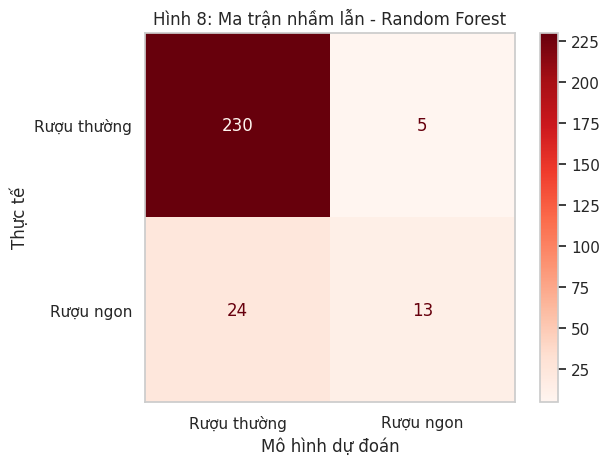

Mô hình chọn 18 chai là rượu ngon, trong đó 13 chai ngon thật (72.2%)
Nếu chọn ngẫu nhiên: chỉ 13.6% là rượu ngon


In [ ]:
# Hình 8: Ma trận nhầm lẫn - so sánh dự đoán của mô hình với thực tế trên tập test
ConfusionMatrixDisplay.from_predictions(y_test, du_doan, display_labels=["Rượu thường", "Rượu ngon"],
                                        cmap="Reds")
plt.title("Hình 8: Ma trận nhầm lẫn - Random Forest")
plt.xlabel("Mô hình dự đoán")
plt.ylabel("Thực tế")
plt.grid(False)
plt.show()

# Trong các chai mô hình chọn là "ngon", bao nhiêu % ngon thật?
chon = du_doan == 1
print(f"Mô hình chọn {chon.sum()} chai là rượu ngon, trong đó {y_test[chon].sum()} chai ngon thật "
      f"({y_test[chon].mean()*100:.1f}%)")
print(f"Nếu chọn ngẫu nhiên: chỉ {y_test.mean()*100:.1f}% là rượu ngon")

**Nhận xét Hình 8 (272 chai trong tập test):**
- **230** chai thường được đoán đúng; **13** chai ngon được tìm ra đúng.
- Chỉ **5** chai thường bị đoán nhầm là ngon, nhưng có tới **24** chai ngon bị bỏ sót.
- Trong 18 chai mô hình chọn là "ngon", có **13 chai ngon thật (72,2%)**, trong khi nếu chọn ngẫu nhiên chỉ được **13,6%** → mô hình chọn đúng rượu ngon **gấp khoảng 5 lần**.
- Tuy nhiên, mô hình chỉ tìm ra **13/37 chai ngon (35%)** → mô hình **chọn ít nhưng khá chính xác**, và bỏ sót phần lớn rượu ngon.
- **Trả lời câu hỏi 1:** có — chỉ dựa vào 11 chỉ số hóa lý, mô hình chọn rượu ngon chính xác hơn nhiều so với chọn ngẫu nhiên → các chỉ số này có chứa thông tin về chất lượng. Nhưng việc bỏ sót nhiều cho thấy chúng **chưa đủ** để nhận ra mọi chai ngon (xem phần phân tích lỗi).

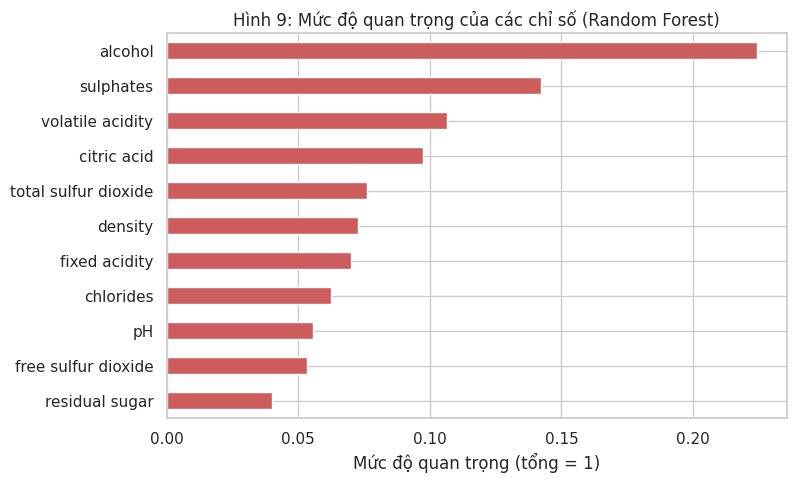

alcohol                 22.4
sulphates               14.2
volatile acidity        10.7
citric acid              9.7
total sulfur dioxide     7.6
density                  7.3
fixed acidity            7.0
chlorides                6.2
pH                       5.5
free sulfur dioxide      5.3
residual sugar           4.0
dtype: float64


In [ ]:
# Hình 9: Mức độ quan trọng của từng chỉ số theo Random Forest
quan_trong = pd.Series(rf.feature_importances_, index=cac_bien).sort_values()
quan_trong.plot(kind="barh", color="indianred", figsize=(8, 5))
plt.title("Hình 9: Mức độ quan trọng của các chỉ số (Random Forest)")
plt.xlabel("Mức độ quan trọng (tổng = 1)")
plt.show()

print((quan_trong.sort_values(ascending=False) * 100).round(1))

**Nhận xét Hình 9 — kết quả kiểm chứng:**

| Thứ hạng | Theo mô hình (Hình 9) | Theo tương quan (Hình 4) |
|---|---|---|
| 1 | alcohol (22,4%) | alcohol (+0,48) |
| 2 | sulphates (14,2%) | volatile acidity (−0,39) |
| 3 | volatile acidity (10,7%) | sulphates (+0,25) |
| 4 | citric acid (9,7%) | citric acid (+0,23) |
| Cuối | **residual sugar (4,0%)** | residual sugar (+0,01) — gần 0 |

- **4 yếu tố đứng đầu giống nhau** ở hai cách xếp hạng (chỉ đổi chỗ hạng 2 và 3), **nồng độ cồn đều đứng đầu** → phù hợp với H1, H2, H3.
- **Đường dư xếp cuối** → phù hợp với H4: độ ngọt không quyết định chất lượng.
- **Trả lời câu hỏi 2:** có — thứ tự quan trọng theo mô hình **gần giống** kết quả kiểm định thống kê, nên nhóm tin tưởng hơn vào các kết luận ở trên.

### Phân tích lỗi: mô hình sai ở đâu và vì sao?

In [ ]:
# Phân tích lỗi (1): mô hình đoán sai nhiều nhất ở những chai có điểm bao nhiêu?
kq = pd.DataFrame({"diem": df_sach.loc[X_test.index, "quality"],
                   "sai": du_doan != y_test})
bang_loi = kq.groupby("diem")["sai"].agg(So_chai="size", So_doan_sai="sum")
bang_loi["Ty_le_sai_%"] = (bang_loi["So_doan_sai"] / bang_loi["So_chai"] * 100).round(1)
bang_loi

,So_chai,So_doan_sai,Ty_le_sai_%
diem,,,
3,2,0,0.0
4,14,0,0.0
5,109,1,0.9
6,110,4,3.6
7,33,23,69.7
8,4,1,25.0


**Nhận xét:**
- Mô hình **không sai chai nào** ở điểm 3 và 4, chỉ sai **0,9%** ở điểm 5 và **3,6%** ở điểm 6 → rượu kém và rượu trung bình gần như **không bị nhầm thành rượu ngon**.
- Gần như toàn bộ lỗi nằm ở **rượu điểm 7**: **23/33 chai (69,7%) bị bỏ sót**; ở điểm 8 sai 1/4 chai.
- **Lưu ý cỡ mẫu:** tập test chỉ có **2 chai điểm 3, 14 chai điểm 4 và 4 chai điểm 8**, nên tỷ lệ sai ở các mức này mới là tín hiệu ban đầu, cần thêm dữ liệu để khẳng định.
- Điều này hợp lý: điểm 7 nằm ngay trên ranh giới với điểm 6 (chỉ cách nhau 1 điểm cảm quan), và nhiều chai 7 điểm có số liệu hóa học gần giống chai 6 điểm → mô hình xếp chúng vào nhóm thường.

In [ ]:
# Phân tích lỗi (2): các chai bị đoán sai "trông" như thế nào về mặt hóa học?
# So sánh trung bình 3 chỉ số quan trọng giữa 4 nhóm: (thực tế) x (mô hình dự đoán)
nhan = {1: "Ngon", 0: "Thường"}
X_test_kq = X_test.assign(Thuc_te=y_test.map(nhan),
                          Du_doan=pd.Series(du_doan, index=X_test.index).map(nhan))

bang_ho_so = X_test_kq.groupby(["Thuc_te", "Du_doan"])[["alcohol", "volatile acidity", "sulphates"]].mean().round(3)
bang_ho_so["So_chai"] = X_test_kq.groupby(["Thuc_te", "Du_doan"]).size()
bang_ho_so

alcohol  volatile acidity  sulphates  So_chai
Thuc_te Du_doan                                               
Ngon    Ngon      12.154             0.393      0.787       13
        Thường    11.346             0.429      0.736       24
Thường  Ngon      11.480             0.296      0.774        5
        Thường    10.254             0.557      0.646      230

**Nhận xét — vì sao mô hình nhầm?**
- **24 chai ngon bị bỏ sót** có nồng độ cồn trung bình chỉ **11,3%**, thấp hơn rõ so với **12,2%** của 13 chai ngon được tìm ra (sulphates cũng thấp hơn: 0,736 so với 0,787) → số liệu của chúng gần với rượu thường hơn.
- Ngược lại, **5 chai thường bị nhầm là ngon** có hồ sơ hóa học **rất tốt**: cồn **11,48%**, độ chua bay hơi chỉ **0,296** — thấp nhất trong cả 4 nhóm, tốt hơn cả những chai ngon bị bỏ sót, nhưng chuyên gia vẫn chỉ cho 6 điểm (nhóm này chỉ có 5 chai nên cần thận trọng).
- **Nhận xét:** ở vùng ranh giới 6–7, **11 chỉ số hóa lý chưa đủ để giải thích** vì sao chuyên gia cho điểm khác nhau. Sự khác biệt có thể đến từ những yếu tố **không có trong dữ liệu**: mùi hương, hậu vị, cảm nhận chủ quan của người chấm… → đây là giới hạn quan trọng của tập dữ liệu (xem mục 4.3).
- **Ứng dụng:** mô hình phù hợp để **sàng lọc sơ bộ** — chai được mô hình chọn là "ngon" có khả năng cao là ngon thật (72%). Nhưng **không nên** dùng mô hình để loại bỏ lô hàng, vì nhiều chai ngon bị xếp nhầm vào nhóm thường; các lô ở vùng ranh giới **vẫn cần chuyên gia nếm thử**.

## 3.7 Tổng hợp kết quả theo từng giả thuyết
Bảng dưới đây tổng hợp lại các bằng chứng đã có ở mục 3.2–3.6 cho **từng giả thuyết**.

| Giả thuyết | Bằng chứng chính | Xem tại | Kết luận |
|---|---|---|---|
| **H1** – Nồng độ cồn cao → điểm cao | r = +0,48 (mạnh nhất), Spearman ρ = +0,49; rượu ngon 11,55% so với 10,26% (+12,6%); t-test p ≈ 2,0 × 10⁻⁴⁰, Mann-Whitney p ≈ 1,2 × 10⁻⁴⁵; quan trọng nhất trong mô hình (22,4%) | Hình 4, 5, 6, 9; mục 3.5 | **Được ủng hộ** — yếu tố mạnh nhất |
| **H2** – Độ chua bay hơi cao → điểm thấp | r = −0,39, ρ = −0,39; rượu ngon 0,406 so với 0,549 (−26,0%); t-test p ≈ 6,5 × 10⁻²⁸, Mann-Whitney p ≈ 8,0 × 10⁻²⁷; hạng 3 trong mô hình (10,7%) | Hình 4, 5, 6, 9; mục 3.5 | **Được ủng hộ** |
| **H3** – Sulphates cao → điểm cao | r = +0,25 nhưng ρ = +0,38 (không tuyến tính); rượu ngon 0,746 so với 0,645 (+15,6%); t-test p ≈ 1,9 × 10⁻¹⁷; tỷ lệ rượu ngon cao nhất ở 0,75–0,85 (34,6%) rồi giảm khi > 1,0 (16,7%); hạng 2 trong mô hình (14,2%) | Hình 4, 5, 9; bảng sulphates (mục 3.3); mục 3.5 | **Được ủng hộ ở mức vừa phải** — quá nhiều không tốt hơn |
| **H4** – Đường dư không ảnh hưởng | r = +0,01, ρ = +0,03; rượu ngon 2,70 so với 2,50; t-test p = 0,056, Mann-Whitney p = 0,054, Spearman p = 0,34; các hộp chồng lên nhau; xếp cuối trong mô hình (4,0%) | Hình 4, 5, 9; mục 3.5 | **Phù hợp với dữ liệu** — chưa có bằng chứng về ảnh hưởng |
| *Phát hiện thêm* – độ chua bay hơi là "điểm trừ", nồng độ cồn là "điểm cộng" | Cồn: rượu lỗi và rượu đạt bằng nhau (10,0%; p = 0,95), rượu ngon cao hơn (p ≈ 3,6 × 10⁻⁴⁵). Độ chua bay hơi: rượu lỗi cao hơn rượu đạt (0,68 so với 0,535; p ≈ 1,5 × 10⁻⁹) | Hình 6; cuối mục 3.5 | **Được kiểm chứng** — rút ra từ dữ liệu, cần kiểm tra thêm |

**Nhận xét:**
- Với cả 4 giả thuyết, biểu đồ, ba phép kiểm định (t-test, Mann-Whitney, Spearman) và mô hình học máy đều cho **cùng một kết luận**.
- Thứ tự mức ảnh hưởng: **nồng độ cồn > độ chua bay hơi ≈ sulphates > đường dư (≈ 0)**.

---
# Giai đoạn 4 — Đánh giá tác động và khuyến nghị
## 4.1 Tóm tắt các phát hiện nổi bật

| # | Phát hiện | Bằng chứng |
|---|---|---|
| 1 | **Nồng độ cồn** là yếu tố quan trọng nhất, là "điểm cộng" giúp rượu trở thành rượu ngon | Tương quan +0,48; rượu ngon nhiều cồn hơn 12,6%; rượu lỗi và rượu đạt có cùng trung vị cồn (10,0%, p ≈ 0,95) nhưng rượu ngon cao hơn rõ (p ≈ 3,6 × 10⁻⁴⁵); đứng đầu về mức độ quan trọng trong mô hình (22,4%) |
| 2 | **Độ chua bay hơi (mùi giấm)** là "điểm trừ" lớn nhất, quyết định rượu có bị chấm kém hay không | Tương quan −0,39; tách rõ rượu lỗi khỏi rượu đạt (trung vị 0,68 so với 0,535; p ≈ 1,5 × 10⁻⁹); nồng độ cồn không tách được hai nhóm này |
| 3 | **Sulphates** có lợi ở mức vừa phải (~0,65–0,85) | Rượu ngon cao hơn 15,6%; tỷ lệ rượu ngon cao nhất (34,6%) ở khoảng 0,75–0,85 rồi giảm còn 16,7% khi > 1,0; Spearman (0,38) cao hơn Pearson (0,25) → quan hệ không tuyến tính; quan trọng thứ 2 trong mô hình |
| 4 | **Không có bằng chứng độ ngọt ảnh hưởng** đến chất lượng | Tương quan 0,01; p-value t-test 0,056, Spearman 0,34; xếp cuối trong mô hình (4,0%) |
| 5 | Kết hợp **cồn > 11% và độ chua bay hơi < 0,5** giúp tăng tỷ lệ gặp rượu ngon từ 7,7% lên **43,2%** | Hình 7 (ngưỡng chọn từ chính dữ liệu, cần kiểm tra thêm) |
| 6 | **Mô hình học máy xác nhận** các kết luận trên; mô hình hầu như không nhầm rượu thường thành rượu ngon, nhưng **bỏ sót nhiều rượu điểm 7** (vùng ranh giới 6–7) | Hình 8–9, phân tích lỗi: chọn đúng 72,2% nhưng chỉ tìm ra 13/37 chai ngon |

## 4.2 Khuyến nghị ứng dụng thực tế
**Đối với nhà sản xuất rượu vang:**
1. **Ưu tiên số 1 — kiểm soát độ chua bay hơi:** đây là lỗi kỹ thuật (do vi khuẩn axetic phát triển khi rượu tiếp xúc với oxy). Cần vệ sinh thiết bị, hạn chế tiếp xúc không khí, kiểm soát nhiệt độ lên men; đặt **ngưỡng nội bộ dưới 0,5 g/dm³** cho các dòng sản phẩm cao cấp.
2. **Nâng nồng độ cồn hướng tới mức ≥ 11%:** thông qua thu hoạch nho đủ độ chín và quy trình lên men hoàn chỉnh.
3. **Dùng sulphates ở mức hợp lý (~0,65–0,85 g/dm³):** đủ để bảo quản, tránh lạm dụng — trên 1,0 g/dm³ tỷ lệ rượu ngon giảm rõ (bảng sulphates ở mục 3.3).
4. **Không cần đầu tư điều chỉnh độ ngọt** để nâng chất lượng.
5. **Kết hợp phòng thí nghiệm và chuyên gia:** dùng các chỉ số hóa lý (hoặc mô hình) để **sàng lọc sơ bộ** — ưu tiên các lô được đánh giá là ngon (mô hình chọn đúng khoảng 72%); dành thời gian của chuyên gia nếm thử cho các lô ở **vùng ranh giới** — nơi số liệu hóa học chưa đủ để kết luận và mô hình hay bỏ sót → tiết kiệm chi phí nếm thử.

**Đối với nhà nhập khẩu / phân phối (ví dụ doanh nghiệp nhập khẩu rượu vào Việt Nam):**
6. Dùng **quy tắc sàng lọc 2 chỉ số** (cồn > 11%, độ chua bay hơi < 0,5) khi xem phiếu phân tích của nhà cung cấp để **ưu tiên lô hàng có khả năng đạt chất lượng cao** — cơ hội chọn được rượu ngon tăng khoảng 5,6 lần (ước tính trên dữ liệu hiện có).

## 4.3 Giới hạn của tập dữ liệu
- **Phạm vi hẹp:** chỉ gồm rượu vang đỏ *Vinho Verde* của Bồ Đào Nha → kết luận chưa chắc đúng với rượu của vùng khác hoặc giống nho khác.
- **Thiếu thông tin kinh tế:** không có giá bán, thương hiệu, giống nho, năm sản xuất (bị ẩn vì lý do bảo mật).
- **Thiếu thông tin cảm quan:** phân tích lỗi cho thấy 11 chỉ số hóa lý **chưa đủ** để phân biệt rượu 6 điểm và 7 điểm — dữ liệu không có mùi hương, hậu vị…
- **Điểm chất lượng mang tính chủ quan:** do chuyên gia nếm thử chấm.
- **Ngưỡng sàng lọc được chọn từ chính dữ liệu:** quy tắc cồn > 11% và độ chua bay hơi < 0,5 cần được kiểm tra trên dữ liệu mới trước khi áp dụng.
- **Mất cân bằng:** rất ít mẫu điểm 3 (10 mẫu) và điểm 8 (17 mẫu, sau khi xóa trùng); tập test chỉ có 37 chai ngon nên kết quả mô hình có thể dao động nếu chia dữ liệu theo cách khác.
- **Tương quan không phải nhân quả:** dữ liệu chỉ cho biết các yếu tố "đi cùng nhau", chưa chứng minh tăng cồn sẽ *gây ra* điểm cao hơn.

## 4.4 Hướng mở rộng trong tương lai
- Bổ sung dữ liệu **rượu vang trắng** (4.898 mẫu) và **giá bán** để đánh giá hiệu quả kinh tế.
- Thu thập thêm **dữ liệu cảm quan** (mùi hương, hậu vị) để giải thích vùng ranh giới 6–7.
- Phát triển mô hình thành **công cụ dự đoán** chất lượng cho lô hàng mới (đánh giá kỹ hơn bằng nhiều lần chia dữ liệu).
- Dự đoán **chính xác từng mức điểm** bằng mô hình thứ bậc (ordinal) khi có thêm mẫu điểm 3–4 và 8.
- Làm **thí nghiệm có kiểm soát** trong sản xuất để kiểm chứng quan hệ nhân quả.

---
**Link GitHub của nhóm:** ………………………………